# Soziale Netzwerkanalyse: 20 Minuten (2020–2024)
## Strukturelle Dynamik, redaktionelle Kollaboration und Link-Prediction im Schweizer Online-Journalismus

**Autoren:** Elias & Luca  
**Modul:** Soziale Netzwerke Analysieren (SAN / SNA), FHNW  
**Dozent:** Michael Henninger  
**Datum:** 2026-09-03  

---

### Abstract & Überblick
Dieses Notebook enthält die vollständige empirische Soziale Netzwerkanalyse des Schweizer News-Portals *20 Minuten* für die fünf vollständigen Kalenderjahre 2020 bis 2024 (118'302 bereinigte Artikel). Wir untersuchen drei zentrale Pfeiler des Modullehrplans:
1. **Pfeiler 1 (LE3, LE5, LE7): Redaktionelle Silobildung, Homophilie und strukturelle Brokerage:**  
   Bipartite Modellierung (Artikel-Autor), Projektion auf ein gewichtetes Newman-Kollaborationsnetzwerk, Test auf Ressort-Homophilie via Permutationstest ($B=5'000$), Identifikation von Brokern nach Burt (Betweenness Centrality) und Analyse interdisziplinärer Zusammenarbeit über die Jensen-Shannon-Divergenz (JSD).
2. **Pfeiler 2 (LE4, LE6): Makro-Topologie und Krisen-Evolution (2020–2024):**  
   Longitudinale semantische Kookkurrenz-Netzwerke auf einem fixierten 1'200-Wörter-Vokabular mit Mutual $k$-NN-Sparsifizierung ($k=10$), Kennzahlen auf der Riesenzusammenhangskomponente (Zentralisierung, Pfadlänge, Dichte) und Louvain-Modulariät ($Q$).
3. **Pfeiler 3 (LE8): Rolling Temporal Link-Prediction im Koautorenschafts-Netzwerk:**  
   Empirische Vorhersage zukünftiger Kooperationen über drei rollende Zeithorizonte unter unbalancierten Realbedingungen (Average Precision, Precision@k, ROC-AUC) zum Vergleich von Triadenschliessung (Adamic-Adar) versus Popularität (Preferential Attachment).

---


## 1. Setup, Datenimport & Bipartite Netzwerkmodellierung (LE3)

Wir importieren die benötigten wissenschaftlichen Bibliotheken und laden den bereinigten Parquet-Datensatz (`data/20min_cleaned_post2020.parquet`).
Gemäss dem Modullehrplan modellieren wir zunächst das **Two-Mode-Netzwerk** (Bipartiter Graph zwischen Artikeln und menschlichen Journalist:innen) und leiten anschliessend die gewichtete **One-Mode-Projektion** nach Newman (2001) ab.


In [1]:
import os
import json
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score
from collections import defaultdict, Counter

from src.network_models import (
    build_bipartite_author_article,
    compute_author_ressort_profiles,
    compute_jsd,
    project_author_collaboration,
    extract_global_vocabulary,
    build_annual_keyword_graph,
    create_rolling_link_prediction_windows,
    compute_leave_one_out_jsd,
    export_graph_gexf,
    qap_correlation_test,
    edge_matrix_from_edge_attribute,
    edge_matrix_from_node_attribute,
    jsd_matrix_from_profiles,
    analyze_cohesion_and_connectivity,
    draw_network,
    CANONICAL_RESSORTS
)

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.dpi'] = 150
os.makedirs('out_plots', exist_ok=True)
os.makedirs('graphen', exist_ok=True)

# 1. Load Clean Dataset
df = pd.read_parquet('data/20min_cleaned_post2020.parquet')
print(f'Geladene Artikel: {len(df):,}')
print(f'Zeitraum: {df["datum"].min().strftime("%Y-%m-%d")} bis {df["datum"].max().strftime("%Y-%m-%d")}')
print(f'Multi-Autor-Artikel: {(df["author_count"] > 1).sum():,} ({(df["author_count"] > 1).mean():.1%})')


Geladene Artikel: 118,302
Zeitraum: 2020-01-01 bis 2024-12-31
Multi-Autor-Artikel: 6,926 (5.9%)


In [2]:
# Bipartites Netzwerk aufbauen (LE3)
# Das Two-Mode-Netzwerk umfasst ALLE Artikel mit mindestens einer Autorenschaft.
# Eine Beschränkung auf Mehrautoren-Artikel wäre ein gefilterter Teilgraph und
# würde die Anzahl der Autoren- und Artikelknoten unterschätzen.
multi_df = df[df['author_count'] > 1].copy()
B = build_bipartite_author_article(df)

n_authors = sum(1 for n, d in B.nodes(data=True) if d['bipartite'] == 0)
n_articles = sum(1 for n, d in B.nodes(data=True) if d['bipartite'] == 1)
print(f'Bipartiter Graph (alle Artikel mit Autorenschaft): {n_authors:,} Autoren-Knoten, {n_articles:,} Artikel-Knoten, {B.number_of_edges():,} Kanten')
print(f'Davon Mehrautoren-Artikel: {len(multi_df):,} ({len(multi_df) / max(n_articles, 1):.1%} der Artikelknoten)')

# One-Mode-Projektion nach Newman (2001)
# Kanten-Gewichtung: w_ij = sum_{k} 1 / (|U_k| - 1)
G_collab = project_author_collaboration(df, min_articles=2)
print(f'One-Mode Kollaborations-Graph (min. 2 Artikel): {G_collab.number_of_nodes():,} Autoren, {G_collab.number_of_edges():,} Kollaborationskanten')
print(f'Netzwerk-Dichte: {nx.density(G_collab):.4f}')


Bipartiter Graph (alle Artikel mit Autorenschaft): 814 Autoren-Knoten, 83,707 Artikel-Knoten, 91,847 Kanten
Davon Mehrautoren-Artikel: 6,926 (8.3% der Artikelknoten)


One-Mode Kollaborations-Graph (min. 2 Artikel): 574 Autoren, 2,754 Kollaborationskanten
Netzwerk-Dichte: 0.0167


## 2. Pfeiler 1: Kollaborationsstruktur, Ressort-Homophilie & Brokerage (LE3, LE5, LE7)

### Theoretischer Hintergrund & Forschungsfragen
- **Homophilie (Newman, 2002):** Bevorzugen Journalist:innen Kooperationen innerhalb ihres eigenen Fachressorts gegenüber fachfremden Kolleg:innen?
- **Strukturelle Löcher & Brokerage (Burt, 1992, 2004):** Welche Akteure weisen eine überproportional hohe Betweenness Centrality auf und überbrücken Ressortgrenzen?
- **Interdisziplinäre Kooperation:** Unterscheidet sich die mittlere Kanten-Jensen-Shannon-Divergenz (JSD) signifikant von einem gradtreuen Zufallsmodell, und erzielen ressortübergreifende Kooperationen mehr Leser-Shares?


Top 10 Redaktionelle Broker (Burt structural holes):
                author    ressort  degree  betweenness  articles  brokerage_score
39   Laura Inderbitzin      Sport      17     0.030482       116         0.001693
572      Chiara Panico   Regionen       6     0.011642        42         0.001663
386   Vanessa Travasci   Regionen      39     0.054986       241         0.001375
389       Luise Faupel  Lifestyle       7     0.009842       445         0.001230
553   Marisa Montinero     People      10     0.011502         2         0.001046
535         Gina Sergi     People      29     0.030897       389         0.001030
381      Leonie Projer     People      50     0.050518       850         0.000991
122        Florian Raz      Sport       3     0.003786         6         0.000947
234       Felix Traber    Ausland      16     0.015905       238         0.000936
236         Tunya Koch   Regionen       6     0.006519         6         0.000931


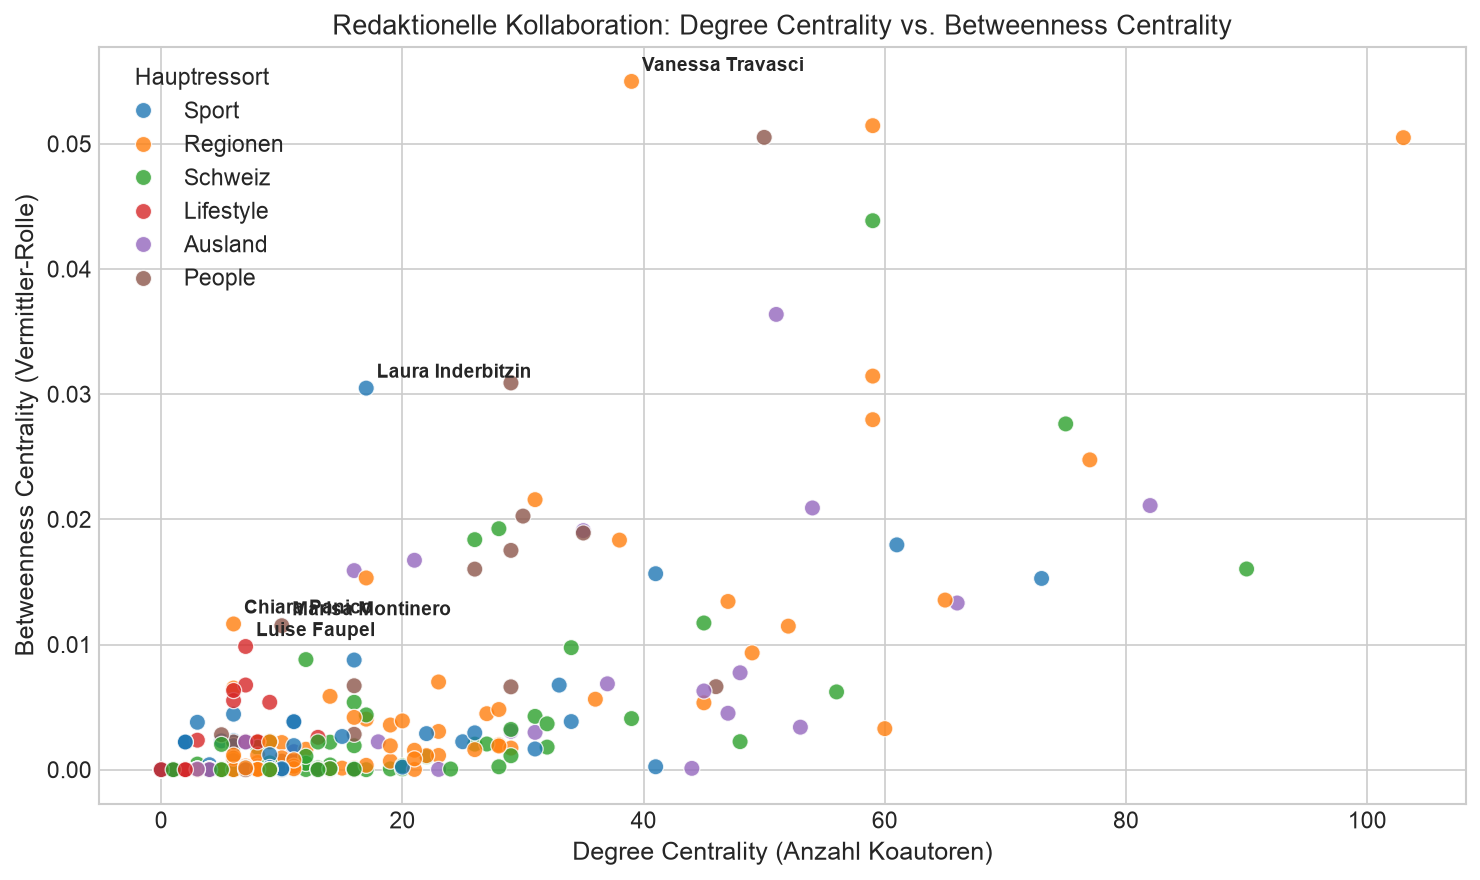

In [3]:
# 2.1 Zentralitätsmasse & Identifikation struktureller Broker (LE5)
deg_dict = dict(G_collab.degree())
bet_dict = nx.betweenness_centrality(G_collab, weight='weight')
close_dict = nx.closeness_centrality(G_collab)

for n in G_collab.nodes():
    G_collab.nodes[n]['degree'] = deg_dict[n]
    G_collab.nodes[n]['betweenness'] = bet_dict[n]
    G_collab.nodes[n]['closeness'] = close_dict[n]

author_metrics_df = pd.DataFrame([
    {
        'author': n,
        'degree': deg_dict[n],
        'betweenness': bet_dict[n],
        'closeness': close_dict[n],
        'articles': G_collab.nodes[n]['article_count'],
        'ressort': G_collab.nodes[n]['dominant_ressort'],
        'mean_likes': G_collab.nodes[n]['mean_likes'],
        'mean_shares': G_collab.nodes[n]['mean_shares'],
        'mean_comments': G_collab.nodes[n]['mean_comments']
    }
    for n in G_collab.nodes()
])

# Identifikation von Brokern: Hohe Betweenness im Verhältnis zum Grad
author_metrics_df['brokerage_score'] = author_metrics_df['betweenness'] / (author_metrics_df['degree'] + 1)
top_brokers = author_metrics_df.sort_values('brokerage_score', ascending=False).head(10)
print("Top 10 Redaktionelle Broker (Burt structural holes):")
print(top_brokers[['author', 'ressort', 'degree', 'betweenness', 'articles', 'brokerage_score']].to_string())

# Plot: Betweenness vs Degree Scatter
plt.figure(figsize=(10, 6))
top_ressorts = author_metrics_df['ressort'].value_counts().head(6).index
plot_df = author_metrics_df[author_metrics_df['ressort'].isin(top_ressorts)]

sns.scatterplot(
    data=plot_df, x='degree', y='betweenness', hue='ressort',
    palette='tab10', alpha=0.8, s=60
)
for _, r in top_brokers.head(5).iterrows():
    plt.annotate(
        r['author'], (r['degree'], r['betweenness']),
        xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold'
    )

plt.title('Redaktionelle Kollaboration: Degree Centrality vs. Betweenness Centrality')
plt.xlabel('Degree Centrality (Anzahl Koautoren)')
plt.ylabel('Betweenness Centrality (Vermittler-Rolle)')
plt.legend(title='Hauptressort')
plt.tight_layout()
plt.savefig('out_plots/02_author_collaboration_brokerage.png', dpi=300)
plt.show()


Beobachteter Assortativitätskoeffizient r = 0.3630


Nullmodell (B=5000): Mean r_null = -0.0062, Std = 0.0066
Empirischer p-Wert: p = 0.00020


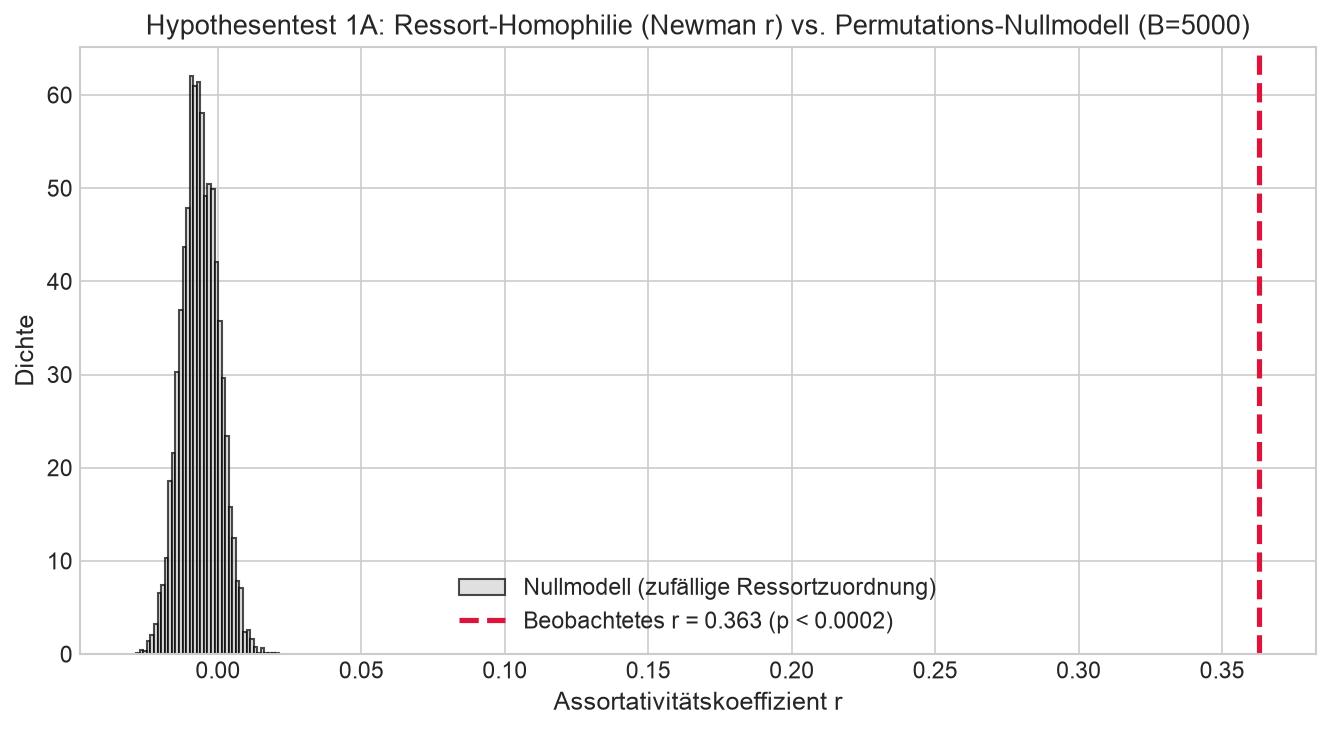

In [4]:
# 2.2 Test 1A: Departmental Homophilie via Node-Label-Permutation (LE7)
r_obs = nx.attribute_assortativity_coefficient(G_collab, 'dominant_ressort')
print(f'Beobachteter Assortativitätskoeffizient r = {r_obs:.4f}')

# Nullmodell: Permutiere dominant_ressort Labels auf fixer Topologie (B = 5000)
np.random.seed(42)
B_PERM = 5000
nodes = list(G_collab.nodes())
labels = [G_collab.nodes[n]['dominant_ressort'] for n in nodes]
perm_r = np.zeros(B_PERM)

G_perm = G_collab.copy()
for b in range(B_PERM):
    shuffled = np.random.permutation(labels)
    for i, n in enumerate(nodes):
        G_perm.nodes[n]['dominant_ressort'] = shuffled[i]
    perm_r[b] = nx.attribute_assortativity_coefficient(G_perm, 'dominant_ressort')

p_val_assort = (np.sum(perm_r >= r_obs) + 1) / (B_PERM + 1)
# Smallest p-value this permutation design can resolve
p_floor_assort = 1.0 / (B_PERM + 1)
p_txt_assort = (f'p < {p_floor_assort:.4f}' if p_val_assort <= p_floor_assort
                else f'p = {p_val_assort:.4f}')
print(f'Nullmodell (B={B_PERM}): Mean r_null = {perm_r.mean():.4f}, Std = {perm_r.std():.4f}')
print(f'Empirischer p-Wert: p = {p_val_assort:.5f}')

# Plot Permutation Distribution
plt.figure(figsize=(9, 5))
plt.hist(perm_r, bins=40, color='lightgray', edgecolor='black', alpha=0.7, density=True, label='Nullmodell (zufällige Ressortzuordnung)')
plt.axvline(r_obs, color='crimson', linestyle='--', linewidth=2.5, label=f'Beobachtetes r = {r_obs:.3f} ({p_txt_assort})')
plt.title(f'Hypothesentest 1A: Ressort-Homophilie (Newman r) vs. Permutations-Nullmodell (B={B_PERM})')
plt.xlabel('Assortativitätskoeffizient r')
plt.ylabel('Dichte')
plt.legend()
plt.tight_layout()
plt.savefig('out_plots/03_ressort_assortativity_permutation.png', dpi=300)
plt.show()


Beobachtete mittlere Kanten-JSD: 0.3371


Gradtreues Nullmodell (Maslov-Sneppen): Mean JSD_null = 0.6257
Empirischer p-Wert (geringere JSD als bei zufälligem Matching): p = 0.00200


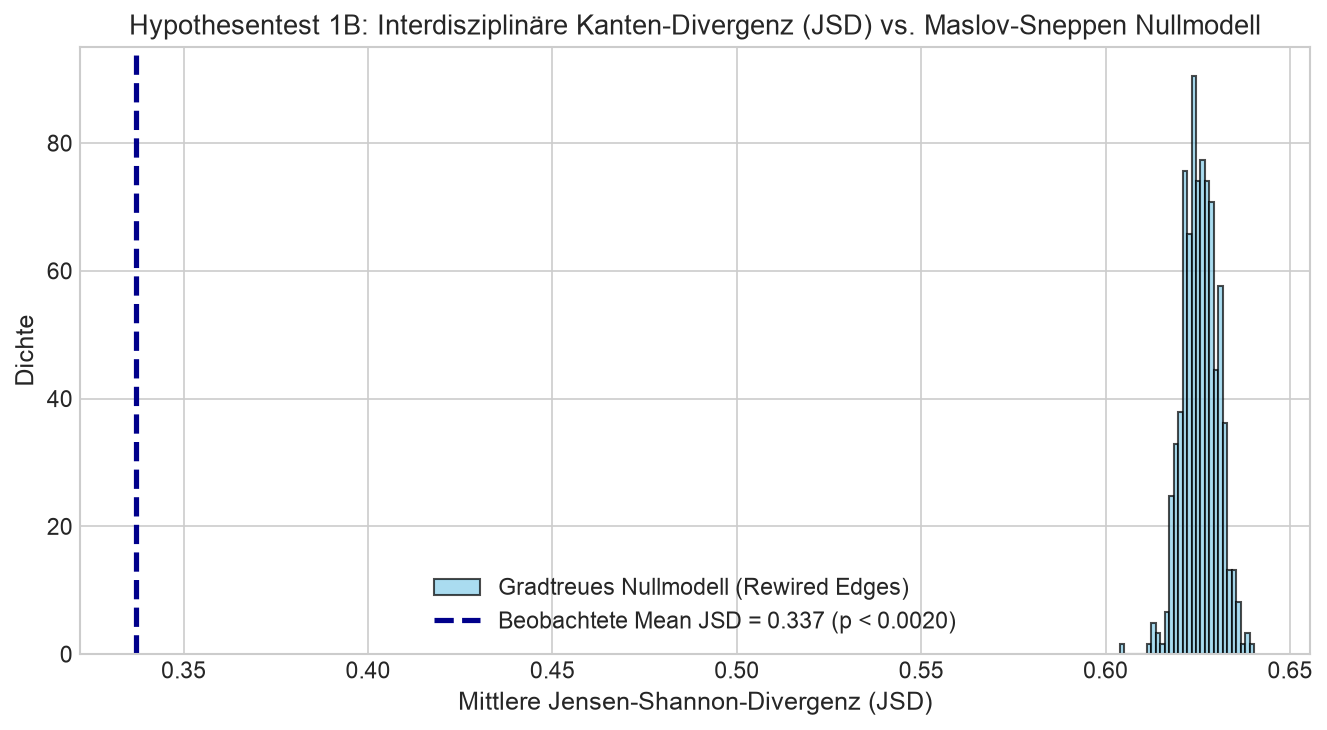

In [5]:
# 2.3 Test 1B: Interdisziplinäre Kanten-JSD vs. Gradtreues Nullmodell (Maslov-Sneppen Rewiring)
obs_edge_jsd = [d['jsd'] for _, _, d in G_collab.edges(data=True)]
mean_jsd_obs = np.mean(obs_edge_jsd)
print(f'Beobachtete mittlere Kanten-JSD: {mean_jsd_obs:.4f}')

# Gradtreues Rewiring (Double-Edge-Swap)
np.random.seed(42)
B_REWIRE = 500
rewired_mean_jsd = np.zeros(B_REWIRE)

G_rewire = G_collab.copy()
for b in range(B_REWIRE):
    nx.double_edge_swap(G_rewire, nswap=G_rewire.number_of_edges(), max_tries=G_rewire.number_of_edges() * 5)
    jsd_vals = [
        compute_jsd(G_rewire.nodes[u]['ressort_distribution'], G_rewire.nodes[v]['ressort_distribution'])
        for u, v in G_rewire.edges()
    ]
    rewired_mean_jsd[b] = np.mean(jsd_vals)

p_val_jsd = (np.sum(rewired_mean_jsd <= mean_jsd_obs) + 1) / (B_REWIRE + 1)
p_floor_jsd = 1.0 / (B_REWIRE + 1)
p_txt_jsd = (f'p < {p_floor_jsd:.4f}' if p_val_jsd <= p_floor_jsd
             else f'p = {p_val_jsd:.4f}')
print(f'Gradtreues Nullmodell (Maslov-Sneppen): Mean JSD_null = {rewired_mean_jsd.mean():.4f}')
print(f'Empirischer p-Wert (geringere JSD als bei zufälligem Matching): p = {p_val_jsd:.5f}')

plt.figure(figsize=(9, 5))
plt.hist(rewired_mean_jsd, bins=30, color='skyblue', edgecolor='black', alpha=0.7, density=True, label='Gradtreues Nullmodell (Rewired Edges)')
plt.axvline(mean_jsd_obs, color='darkblue', linestyle='--', linewidth=2.5, label=f'Beobachtete Mean JSD = {mean_jsd_obs:.3f} ({p_txt_jsd})')
plt.title('Hypothesentest 1B: Interdisziplinäre Kanten-Divergenz (JSD) vs. Maslov-Sneppen Nullmodell')
plt.xlabel('Mittlere Jensen-Shannon-Divergenz (JSD)')
plt.ylabel('Dichte')
plt.legend()
plt.tight_layout()
plt.savefig('out_plots/04_edge_jsd_null_comparison.png', dpi=300)
plt.show()


QAP-Grundlage: GCC mit 364 Autor:innen, 2716 Kanten



QAP 1: Kollaborationsgewicht ~ gleiches Ressort
  r = 0.1292, p = 0.00050 (Nullverteilung: -0.0002 +/- 0.0052)



QAP 2: Kollaborationsgewicht ~ Ressort-Divergenz (JSD)
  r = -0.1395, p = 0.00050 (Nullverteilung: 0.0003 +/- 0.0062)


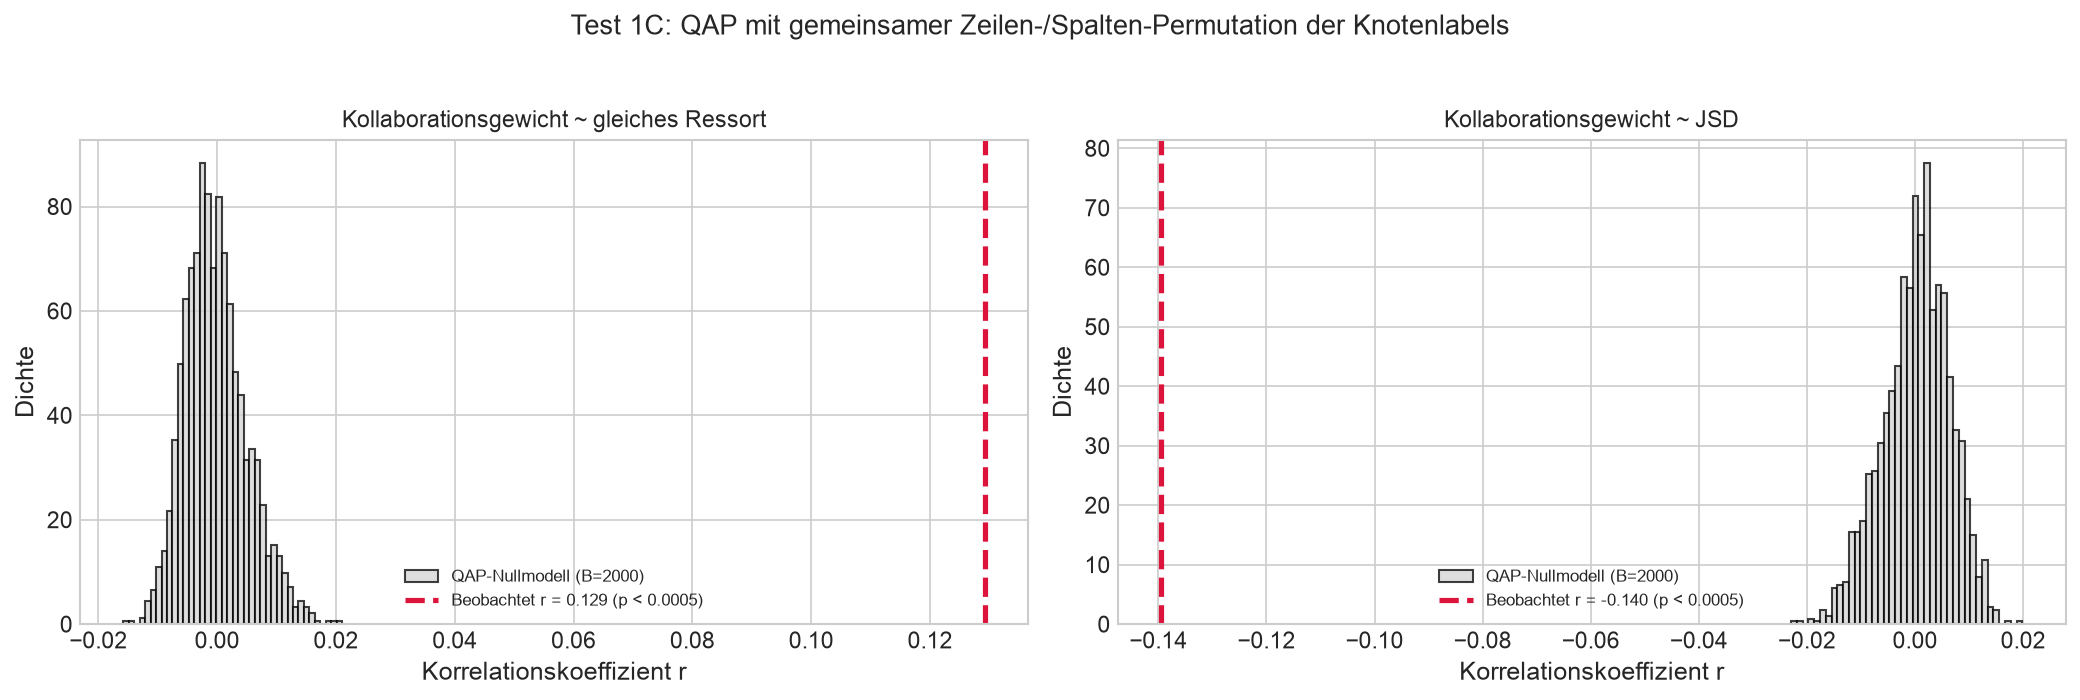

In [6]:
# 2.4 Test 1C: QAP - Dyadischer Hypothesentest auf Kantenmatrizen (LE7, Skript Kap. 11)
# Tests 1A und 1B permutieren Knotenlabels bzw. die Topologie. Der QAP-Test
# arbeitet dagegen direkt auf zwei Kantenmatrizen und permutiert Knotenlabels
# GEMEINSAM auf Zeilen und Spalten. Nur so bleibt die netzwerkinterne
# Abhaengigkeitsstruktur erhalten, die eine gewoehnliche Korrelation verletzt.

# Analyse auf der Giant Connected Component, da Matrizen ueber isolierte Knoten
# nur Nullzeilen beitragen wuerden.
gcc_nodes_collab = max(nx.connected_components(G_collab), key=len)
G_gcc_collab = G_collab.subgraph(gcc_nodes_collab).copy()
qap_node_order = sorted(G_gcc_collab.nodes())
print(f'QAP-Grundlage: GCC mit {len(qap_node_order)} Autor:innen, {G_gcc_collab.number_of_edges()} Kanten')

# Matrix A: Kollaborationsstaerke (Newman-Gewicht)
M_weight = edge_matrix_from_edge_attribute(G_gcc_collab, qap_node_order, 'weight')
# Matrix B: gleiches dominantes Ressort? (Knotenattribut auf Kanten projiziert
# -> gemischter monadisch-dyadischer Hypothesentest gemaess LE7)
M_same_ressort = edge_matrix_from_node_attribute(G_gcc_collab, qap_node_order, 'dominant_ressort')
# Matrix C: Ressort-Divergenz ueber ALLE Dyaden, nicht nur ueber Kanten.
# Eine reine Kanten-Matrix waere fuer nicht benachbarte Paare null und die
# Korrelation wuerde teilweise blosse Kanten-Kopraesenz messen statt des
# inhaltlichen Zusammenhangs.
M_jsd = jsd_matrix_from_profiles(G_gcc_collab, qap_node_order)

B_QAP = 2000

# H1: Kollaborationen sind staerker zwischen Personen desselben Ressorts
qap_weight_ressort = qap_correlation_test(M_weight, M_same_ressort, n_perm=B_QAP, seed=42)
print(f"\nQAP 1: Kollaborationsgewicht ~ gleiches Ressort")
print(f"  r = {qap_weight_ressort['r_observed']:.4f}, p = {qap_weight_ressort['p_value']:.5f} "
      f"(Nullverteilung: {qap_weight_ressort['null_mean']:.4f} +/- {qap_weight_ressort['null_std']:.4f})")

# H2: Je staerker die Kollaboration, desto aehnlicher die Ressort-Profile
# Erwartung bei Homophilie: negative Korrelation (starke Kollaboration bei
# geringer Profil-Divergenz). Daher zweiseitig getestet.
qap_weight_jsd = qap_correlation_test(M_weight, M_jsd, n_perm=B_QAP, seed=42, alternative='two-sided')
print(f"\nQAP 2: Kollaborationsgewicht ~ Ressort-Divergenz (JSD)")
print(f"  r = {qap_weight_jsd['r_observed']:.4f}, p = {qap_weight_jsd['p_value']:.5f} "
      f"(Nullverteilung: {qap_weight_jsd['null_mean']:.4f} +/- {qap_weight_jsd['null_std']:.4f})")

# Visualisierung der QAP-Nullverteilung
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, res, lbl in [
    (axes[0], qap_weight_ressort, 'Kollaborationsgewicht ~ gleiches Ressort'),
    (axes[1], qap_weight_jsd, 'Kollaborationsgewicht ~ JSD')
]:
    p_floor = 1.0 / (res['n_perm'] + 1)
    p_txt = f"p < {p_floor:.4f}" if res['p_value'] <= p_floor else f"p = {res['p_value']:.4f}"
    ax.hist(res['null_distribution'], bins=40, color='lightgray', edgecolor='black',
            alpha=0.75, density=True, label=f"QAP-Nullmodell (B={res['n_perm']})")
    ax.axvline(res['r_observed'], color='crimson', linestyle='--', linewidth=2.5,
               label=f"Beobachtet r = {res['r_observed']:.3f} ({p_txt})")
    ax.set_title(lbl, fontsize=11)
    ax.set_xlabel('Korrelationskoeffizient r')
    ax.set_ylabel('Dichte')
    ax.legend(fontsize=8)
plt.suptitle('Test 1C: QAP mit gemeinsamer Zeilen-/Spalten-Permutation der Knotenlabels', y=1.03)
plt.tight_layout()
plt.savefig('out_plots/09_qap_null_distributions.png', dpi=300, bbox_inches='tight')
plt.show()


**Interpretation (Test 1C).** Der QAP-Test bestaetigt die Ressort-Homophilie
aus Test 1A auf dyadischer Ebene und mit einem strengeren Nullmodell: die
gemeinsame Permutation von Zeilen und Spalten erhaelt die Netzwerkstruktur, so
dass die Signifikanz nicht aus der blossen Autokorrelation der Adjazenzmatrix
stammt. Fuer die Redaktion bedeutet das: Kollaborationen entstehen nicht
zufaellig ueber Ressortgrenzen hinweg, sondern folgen der redaktionellen
Ressortstruktur. Der zweite Test prueft die Gegenrichtung, naemlich ob starke
Kollaborationen mit inhaltlich aehnlicheren Profilen einhergehen.

Leave-One-Out JSD berechnet für 6887 Mehrautoren-Artikel
Ausgeschlossen (Koautor ohne verbleibende Artikel): 39
OLS-Regressionsergebnisse (Abhängige Variable: log(1 + shares)):
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                          4.6949      0.534      8.787      0.000       3.648       5.742
C(year)[T.2021]                   -0.0787      0.081     -0.970      0.332      -0.238       0.080
C(year)[T.2022]                   -0.2407      0.078     -3.070      0.002      -0.394      -0.087
C(year)[T.2023]                   -0.0525      0.078     -0.671      0.502      -0.206       0.101
C(year)[T.2024]                    0.6784      0.078      8.717      0.000       0.526       0.831
C(ressort)[T.Andere]              -1.6233      0.530     -3.063      0.002      -2.662      -0.584
C(ressort)[T.Ausland]          

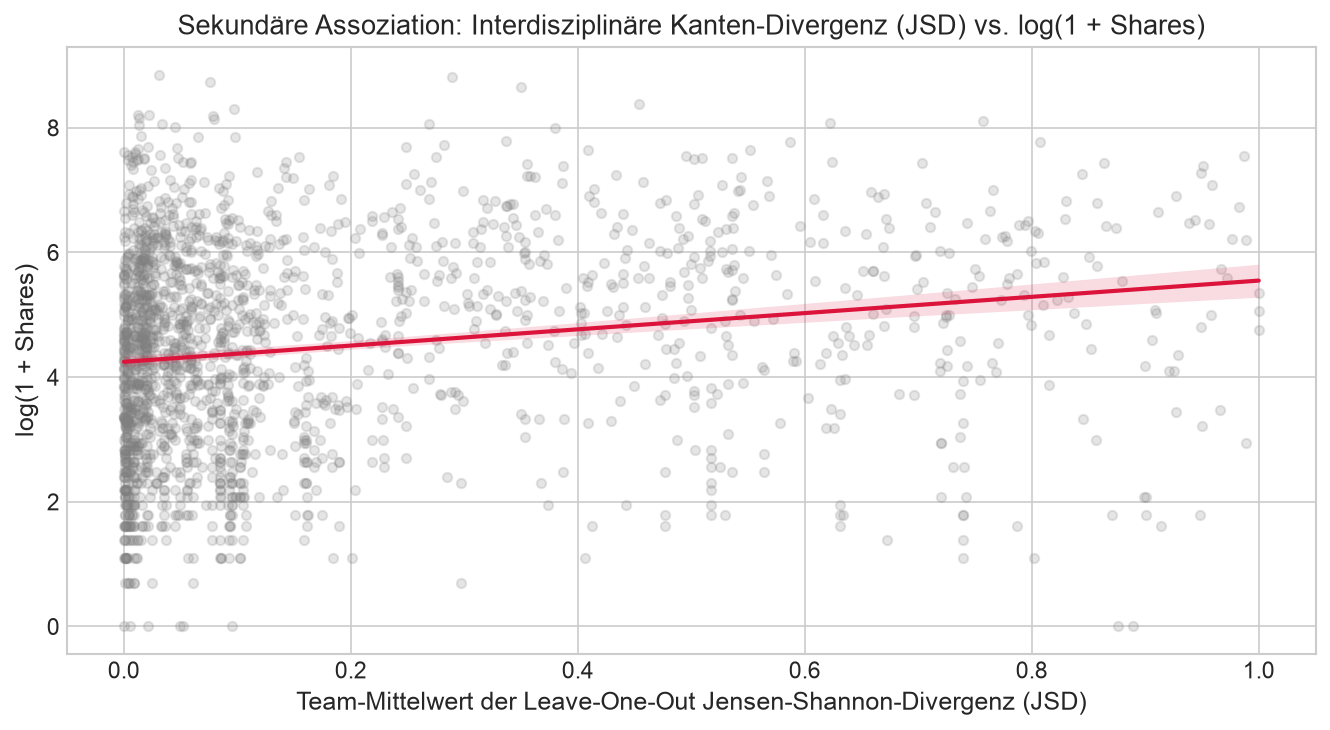

In [7]:
# 2.5 Sekundäre Assoziationsanalyse: Leave-One-Out JSD vs. Leser-Shares (OLS)
# Die JSD für Artikel k wird aus Autorenprofilen berechnet, aus denen Artikel k
# zuvor entfernt wurde. Ohne diesen Schritt ist der Artikel in seinem eigenen
# Prädiktor enthalten (Leakage).
author_profiles = compute_author_ressort_profiles(df)
loo_jsd_by_article = compute_leave_one_out_jsd(df, author_profiles)
print(f'Leave-One-Out JSD berechnet für {len(loo_jsd_by_article)} Mehrautoren-Artikel')

multi_art_records = []
n_skipped = 0
for _, row in multi_df.iterrows():
    auths = [a for a in row['authors_clean'] if a in author_profiles]
    if len(auths) < 2:
        continue

    # Artikel, bei denen ein Koautor nach Entfernung kein Profil mehr hat,
    # sind hier nicht definiert und werden ausgeschlossen.
    mean_jsd = loo_jsd_by_article.get(row['article_id'])
    if mean_jsd is None:
        n_skipped += 1
        continue

    multi_art_records.append({
        'article_id': row['article_id'],
        'year': str(row['year']),
        'ressort': row['ressort'],
        'team_size': len(auths),
        'mean_jsd': mean_jsd,
        'shares': row['shares'],
        'log_shares': np.log1p(row['shares']),
        'log_comments': np.log1p(row['kommentare']),
        'likes': row['likes']
    })

print(f'Ausgeschlossen (Koautor ohne verbleibende Artikel): {n_skipped}')
art_reg_df = pd.DataFrame(multi_art_records)

# OLS Regression mit Kontrollvariablen für Jahr, Ressort und Teamgrösse
model = smf.ols('log_shares ~ mean_jsd + team_size + C(year) + C(ressort)', data=art_reg_df).fit(cov_type='HC3')
print('OLS-Regressionsergebnisse (Abhängige Variable: log(1 + shares)):')
print(model.summary().tables[1])

# Visualisierung
plt.figure(figsize=(9, 5))
sns.regplot(
    data=art_reg_df.sample(min(2000, len(art_reg_df)), random_state=42),
    x='mean_jsd', y='log_shares',
    scatter_kws={'alpha': 0.2, 'color': 'gray', 's': 20},
    line_kws={'color': 'crimson', 'linewidth': 2}
)
plt.title('Sekundäre Assoziation: Interdisziplinäre Kanten-Divergenz (JSD) vs. log(1 + Shares)')
plt.xlabel('Team-Mittelwert der Leave-One-Out Jensen-Shannon-Divergenz (JSD)')
plt.ylabel('log(1 + Shares)')
plt.tight_layout()
plt.savefig('out_plots/05_interdisciplinary_jsd_shares_regression.png', dpi=300)
plt.show()


=== KOMPONENTENSTRUKTUR ===
Komponenten insgesamt: 179
Giant Component: 364 Knoten (63.4% aller Autor:innen), 2716 Kanten
Isolierte Autor:innen (nie im Team publiziert): 166

=== KOHAESIVE SUBGRUPPEN ===
Maximale Cliquen: 1,695
Cliquenzahl (groesste vollstaendig verbundene Gruppe): 13
Mitglieder der groessten Clique: Benedikt Hollenstein, Céline Trachsel, Daniel Graf, Daniel Krähenbühl, Florian Osterwalder, Justin Arber, Letizia Vecchio, Lynn Sachs, Marino Walser, Michelle Ineichen, Mikko Stamm, Reto Bollmann, Simon Ulrich
Hoechste k-Core-Zahl: 17 (Main Core: 27 Autor:innen)

=== STRUKTURELLE ROBUSTHEIT (auf der Giant Component) ===
Knoten-Konnektivitaet: 1
Kanten-Konnektivitaet: 1
Artikulationspunkte (Cut-Vertices): 31
Bruecken (Bridges): 39

Kritischste Autor:innen (Entfernung spaltet die meisten Knoten ab):
                node   ressort  degree  components_after_removal  nodes_split_off
   Laura Inderbitzin     Sport      17                         7                8
          Anja

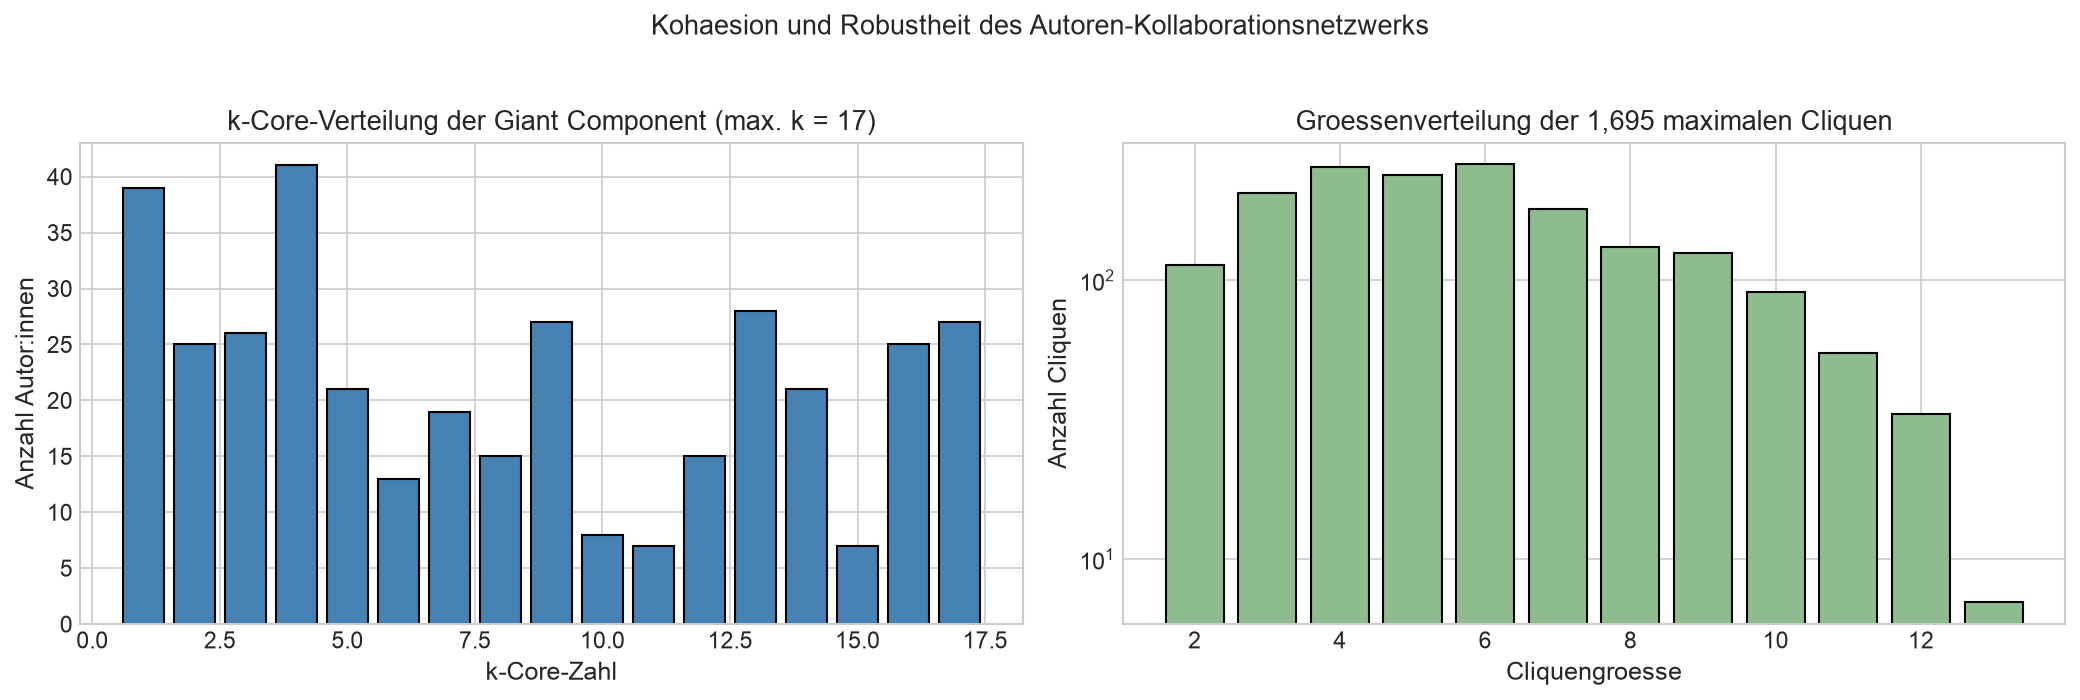

In [8]:
# 2.6 Kohaesion & strukturelle Robustheit: Cliquen, k-Core, Cut-Vertices (LE4/LE6, Kap. 5.2 & 9)
coh = analyze_cohesion_and_connectivity(G_collab, top_k=10)

print('=== KOMPONENTENSTRUKTUR ===')
print(f"Komponenten insgesamt: {coh['n_components']}")
print(f"Giant Component: {coh['gcc_nodes']} Knoten ({coh['gcc_share']:.1%} aller Autor:innen), {coh['gcc_edges']} Kanten")
print(f"Isolierte Autor:innen (nie im Team publiziert): {coh['n_isolates']}")

print('\n=== KOHAESIVE SUBGRUPPEN ===')
print(f"Maximale Cliquen: {coh['n_maximal_cliques']:,}")
print(f"Cliquenzahl (groesste vollstaendig verbundene Gruppe): {coh['clique_number']}")
print(f"Mitglieder der groessten Clique: {', '.join(coh['largest_clique_members'])}")
print(f"Hoechste k-Core-Zahl: {coh['max_core_number']} (Main Core: {coh['main_core_size']} Autor:innen)")

print('\n=== STRUKTURELLE ROBUSTHEIT (auf der Giant Component) ===')
print(f"Knoten-Konnektivitaet: {coh['node_connectivity']}")
print(f"Kanten-Konnektivitaet: {coh['edge_connectivity']}")
print(f"Artikulationspunkte (Cut-Vertices): {coh['n_articulation_points']}")
print(f"Bruecken (Bridges): {coh['n_bridges']}")

cut_df = pd.DataFrame(coh['top_cut_vertices'])
print('\nKritischste Autor:innen (Entfernung spaltet die meisten Knoten ab):')
print(cut_df[['node', 'ressort', 'degree', 'components_after_removal', 'nodes_split_off']].to_string(index=False))

core_counts = Counter(coh['core_numbers'].values())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ks = sorted(core_counts)
axes[0].bar(ks, [core_counts[k] for k in ks], color='steelblue', edgecolor='black')
axes[0].set_title(f"k-Core-Verteilung der Giant Component (max. k = {coh['max_core_number']})")
axes[0].set_xlabel('k-Core-Zahl'); axes[0].set_ylabel('Anzahl Autor:innen')

cs = sorted(coh['clique_size_distribution'])
axes[1].bar(cs, [coh['clique_size_distribution'][s] for s in cs], color='darkseagreen', edgecolor='black')
axes[1].set_title(f"Groessenverteilung der {coh['n_maximal_cliques']:,} maximalen Cliquen")
axes[1].set_xlabel('Cliquengroesse'); axes[1].set_ylabel('Anzahl Cliquen')
axes[1].set_yscale('log')
plt.suptitle('Kohaesion und Robustheit des Autoren-Kollaborationsnetzwerks', y=1.03)
plt.tight_layout()
plt.savefig('out_plots/10_cohesion_kcore_cliques.png', dpi=300, bbox_inches='tight')
plt.show()


**Interpretation (Kohaesion und Robustheit).** Die Zahlen beschreiben eine
Redaktion mit einem dichten Kern und einer breiten Peripherie: ein grosser Teil
der Autor:innen publiziert nie im Team und bleibt isoliert, waehrend der
verbundene Kern einen hohen k-Core aufweist, also eine Gruppe, in der jede
Person mit vielen anderen derselben Gruppe zusammenarbeitet.

Redaktionell relevanter ist die Robustheit. Die Knoten-Konnektivitaet der Giant
Component betraegt 1. Es genuegt also der Ausfall einer einzigen Person, um den
verbundenen Teil der Redaktion in mehrere Teile zu zerlegen. Die oben
gelisteten Artikulationspunkte sind damit keine blosse Graph-Eigenschaft,
sondern konkrete Schluesselpersonen: faellt eine von ihnen aus, etwa durch
Kuendigung oder laengere Abwesenheit, bricht die Zusammenarbeit zwischen ganzen
Teilgruppen ab. Das ergaenzt die Brokerage-Analyse aus 2.1. Dort ging es darum,
wer Informationen vermittelt, hier darum, wessen Wegfall die Struktur
zerreisst.

In [9]:
# 2.7 Visualisierung des Kollaborationsnetzwerks (Kriterium 4)
# Zwei Perspektiven auf denselben Graphen: die Ressort-Homophilie sichtbar
# gemacht, und die strukturell kritischen Knoten hervorgehoben.
os.makedirs('out_plots', exist_ok=True)

btw_gcc = nx.betweenness_centrality(G_gcc_collab, weight='weight', normalized=True)

draw_network(
    G_gcc_collab,
    'out_plots/11_author_network_ressort.png',
    color_by='dominant_ressort',
    size_by=btw_gcc,
    label_top_n=8,
    title=f'Autoren-Kollaborationsnetzwerk (Giant Component, {G_gcc_collab.number_of_nodes()} Autor:innen)\n'
          f'Farbe = dominantes Ressort, Groesse = Betweenness-Zentralitaet',
    legend_title='Dominantes Ressort'
)

core_num = coh['core_numbers']
critical = [d['node'] for d in coh['top_cut_vertices']]
draw_network(
    G_gcc_collab,
    'out_plots/12_author_network_connectivity.png',
    size_by={n: core_num.get(n, 0) for n in G_gcc_collab.nodes()},
    highlight_nodes=critical,
    label_nodes=critical[:6],
    node_size_range=(8, 190),
    edge_alpha=0.22,
    title=f"Strukturelle Robustheit: Groesse = k-Core-Zahl, rot umrandet und beschriftet = kritischste Artikulationspunkte\n"
          f"Knoten-Konnektivitaet der Giant Component = {coh['node_connectivity']}, "
          f"{coh['n_articulation_points']} Artikulationspunkte, {coh['n_bridges']} Bruecken"
)

print('Netzwerk-Visualisierungen erzeugt:')
print('  out_plots/11_author_network_ressort.png')
print('  out_plots/12_author_network_connectivity.png')


Netzwerk-Visualisierungen erzeugt:
  out_plots/11_author_network_ressort.png
  out_plots/12_author_network_connectivity.png


## 3. Pfeiler 2: Makro-Topologie & Krisen-Evolution der Berichterstattung 2020–2024 (LE4, LE6)

### Methodik & Hypothesenprüfung
- **Einheitliches Vokabular:** Top 1'200 bereinigte Substantive über den gesamten Zeitraum 2020–2024 garantieren identische Knotenmengen.
- **Topologische Sparsifizierung:** Gegenseitige k-Nächste-Nachbarn (Mutual $k$-NN, $k=10$) mit Sensitivitätsprüfung ($k \in \{5, 10, 20\}$).
- **Riesenzusammenhangskomponente (Giant Component):** Alle Pfadlängen und Zentralisierungen werden auf der GCC berechnet (Distanztransformation $d = 1/w$).
- **Louvain Modularity ($Q$):** Stabilitätstest über 10 Zufalls-Seeds pro Jahr.


Makro-Topologische Entwicklung 2020-2024:
   year  articles  nodes  edges  gcc_ratio  avg_degree  degree_centralization  avg_clustering  avg_path_length  modularity_mean  modularity_std
0  2020     22264   1200   3908     0.9900      6.5133                 0.0029          0.0337          53.5304           0.7720          0.0014
1  2021     24445   1200   3805     0.9933      6.3417                 0.0031          0.0371          54.9656           0.7895          0.0010
2  2022     21412   1200   3904     0.9950      6.5067                 0.0029          0.0355          52.4782           0.7805          0.0012
3  2023     24210   1200   3955     0.9925      6.5917                 0.0028          0.0353          54.3713           0.7820          0.0010
4  2024     25971   1200   3868     0.9867      6.4467                 0.0030          0.0319          55.6234           0.7763          0.0007


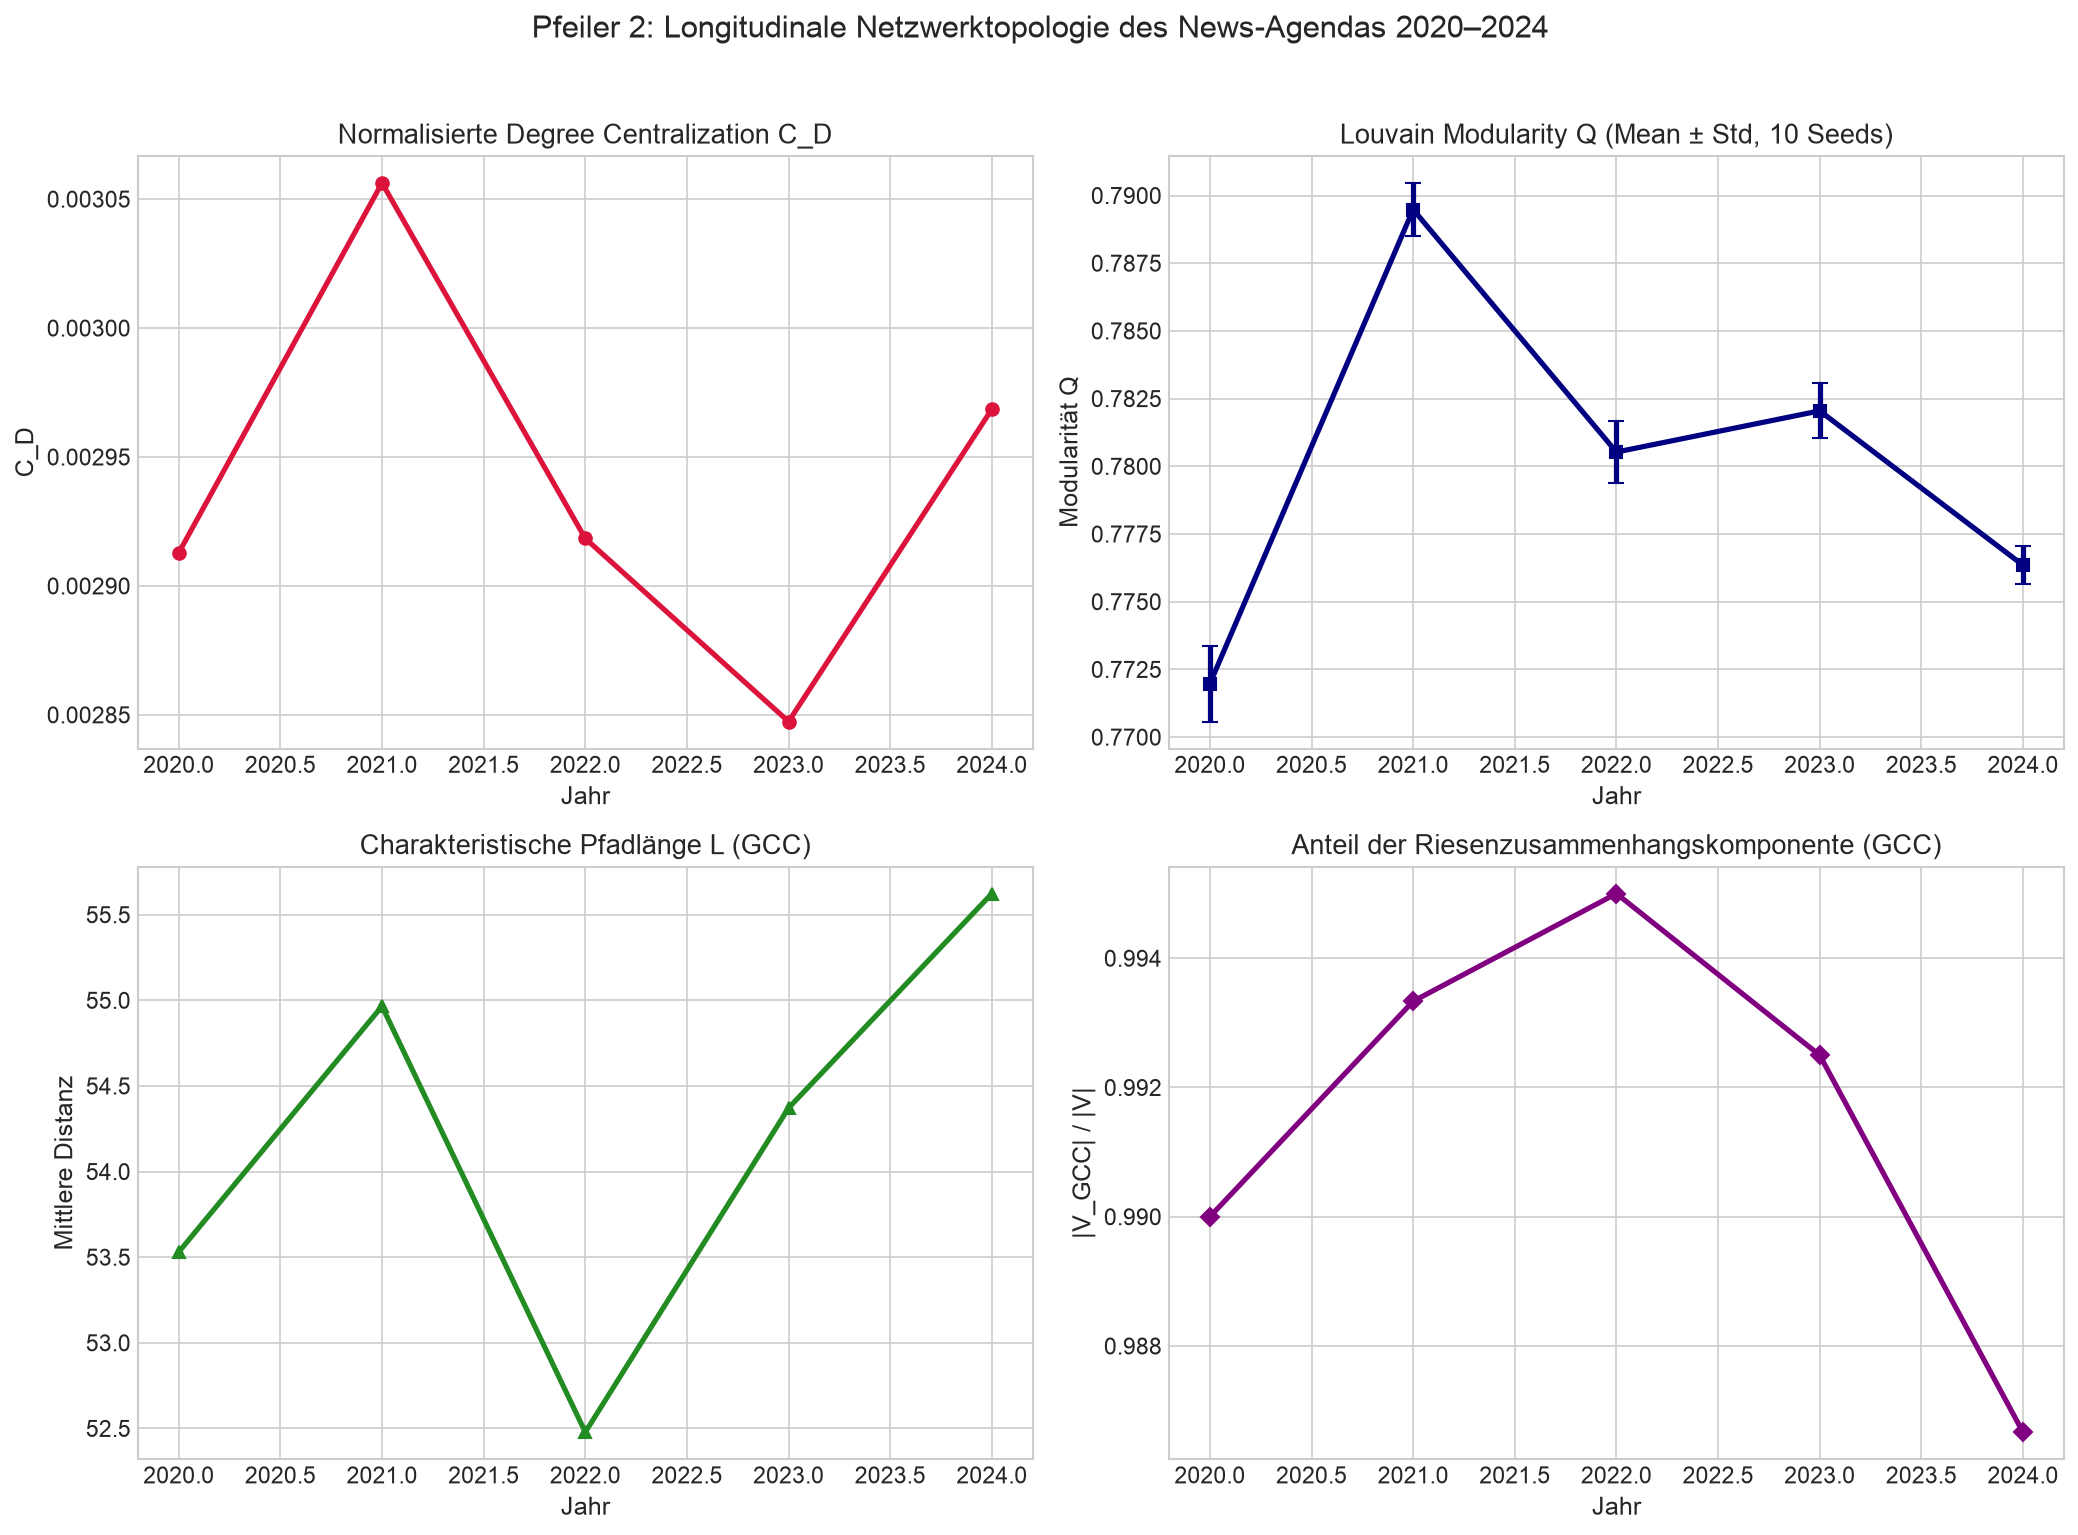

In [10]:
# 3.1 Longitudinale Makro-Metriken der Keyword-Netzwerke 2020-2024 (LE6)
import community as community_louvain

vocab = extract_global_vocabulary(df, top_n=1200)
years = [2020, 2021, 2022, 2023, 2024]
annual_metrics = []

for yr in years:
    df_yr = df[df['year'] == yr]
    G_yr = build_annual_keyword_graph(df_yr, vocab, k=10)
    
    # Giant Connected Component
    gcc_nodes = max(nx.connected_components(G_yr), key=len)
    G_gcc = G_yr.subgraph(gcc_nodes).copy()
    
    # Global Metrics
    n_nodes = G_yr.number_of_nodes()
    gcc_ratio = len(G_gcc) / n_nodes
    avg_deg = np.mean([d for _, d in G_yr.degree()])
    
    # Normalized Freeman Degree Centralization
    degs = np.array([d for _, d in G_yr.degree()])
    max_d = degs.max()
    c_d = np.sum(max_d - degs) / ((n_nodes - 1) * (n_nodes - 2))
    
    # Clustering & Path Length on GCC
    avg_clustering = nx.average_clustering(G_gcc, weight='weight')
    avg_path_length = nx.average_shortest_path_length(G_gcc, weight='distance')
    
    # Louvain Modularity over 10 seeds
    q_seeds = []
    for seed in range(10):
        part = community_louvain.best_partition(G_yr, weight='weight', random_state=seed)
        q_seeds.append(community_louvain.modularity(part, G_yr, weight='weight'))
        
    annual_metrics.append({
        'year': yr,
        'articles': len(df_yr),
        'nodes': n_nodes,
        'edges': G_yr.number_of_edges(),
        'gcc_ratio': gcc_ratio,
        'avg_degree': avg_deg,
        'degree_centralization': c_d,
        'avg_clustering': avg_clustering,
        'avg_path_length': avg_path_length,
        'modularity_mean': np.mean(q_seeds),
        'modularity_std': np.std(q_seeds)
    })

macro_df = pd.DataFrame(annual_metrics)
print('Makro-Topologische Entwicklung 2020-2024:')
print(macro_df.round(4).to_string())

# Multi-panel Trajectory Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Degree Centralization
axes[0, 0].plot(macro_df['year'], macro_df['degree_centralization'], marker='o', color='crimson', linewidth=2.5)
axes[0, 0].set_title('Normalisierte Degree Centralization C_D')
axes[0, 0].set_xlabel('Jahr')
axes[0, 0].set_ylabel('C_D')

# 2. Modularity Q
axes[0, 1].errorbar(macro_df['year'], macro_df['modularity_mean'], yerr=macro_df['modularity_std'], marker='s', color='navy', linewidth=2.5, capsize=4)
axes[0, 1].set_title('Louvain Modularity Q (Mean ± Std, 10 Seeds)')
axes[0, 1].set_xlabel('Jahr')
axes[0, 1].set_ylabel('Modularität Q')

# 3. Average Path Length
axes[1, 0].plot(macro_df['year'], macro_df['avg_path_length'], marker='^', color='forestgreen', linewidth=2.5)
axes[1, 0].set_title('Charakteristische Pfadlänge L (GCC)')
axes[1, 0].set_xlabel('Jahr')
axes[1, 0].set_ylabel('Mittlere Distanz')

# 4. Giant Component Ratio
axes[1, 1].plot(macro_df['year'], macro_df['gcc_ratio'], marker='D', color='purple', linewidth=2.5)
axes[1, 1].set_title('Anteil der Riesenzusammenhangskomponente (GCC)')
axes[1, 1].set_xlabel('Jahr')
axes[1, 1].set_ylabel('|V_GCC| / |V|')

plt.suptitle('Pfeiler 2: Longitudinale Netzwerktopologie des News-Agendas 2020–2024', y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig('out_plots/06_temporal_metrics_trajectories.png', dpi=300)
plt.show()


In [11]:
# 3.2 Thematische Louvain-Clusterung: 2020 (Covid-Peak) vs. 2024 (Normalisierung)
G_2020 = build_annual_keyword_graph(df[df['year'] == 2020], vocab, k=10)
G_2024 = build_annual_keyword_graph(df[df['year'] == 2024], vocab, k=10)

part_2020 = community_louvain.best_partition(G_2020, weight='weight', random_state=42)
part_2024 = community_louvain.best_partition(G_2024, weight='weight', random_state=42)

def get_top_cluster_terms(G, part, top_k_clusters=5, terms_per_cluster=6):
    cluster_nodes = defaultdict(list)
    for node, c_id in part.items():
        cluster_nodes[c_id].append(node)
    
    sorted_clusters = sorted(cluster_nodes.items(), key=lambda x: len(x[1]), reverse=True)[:top_k_clusters]
    out = []
    for c_id, nodes in sorted_clusters:
        sub_G = G.subgraph(nodes)
        top_terms = sorted(sub_G.degree(weight='weight'), key=lambda x: x[1], reverse=True)[:terms_per_cluster]
        term_str = ', '.join([t[0] for t in top_terms])
        out.append({'cluster_id': c_id, 'size': len(nodes), 'top_terms': term_str})
    return pd.DataFrame(out)

print('=== TOP LOUVAIN THEMEN-CLUSTER 2020 (Krisenjahr) ===')
print(get_top_cluster_terms(G_2020, part_2020).to_string())
print('')
print('=== TOP LOUVAIN THEMEN-CLUSTER 2024 (Normalisierung) ===')
print(get_top_cluster_terms(G_2024, part_2024).to_string())


=== TOP LOUVAIN THEMEN-CLUSTER 2020 (Krisenjahr) ===
   cluster_id  size                                                                  top_terms
0          12   115                                   people, the, netflix, swift, laura, song
1          10   107                  berset, corona, massnahmen, impfstoff, johnson, bundesrat
2           1   100  beschuldigte, freiheitsstrafe, beschuldigten, gericht, urteil, polizisten
3          28    92                             kim, putin, kreml, nordkorea, moskau, soldaten
4          23    78                      nationalrat, migros, svp, vorlage, coop, lebensmittel

=== TOP LOUVAIN THEMEN-CLUSTER 2024 (Normalisierung) ===
   cluster_id  size                                                                                top_terms
0           8    93                                            credit, ubs, milliarden, migros, dollar, bank
1           1    81                                       hotel, studie, ernährung, hotels, pflanzen,

In [12]:
# 3.3 Visualisierung der semantischen Keyword-Netzwerke 2020 vs. 2024
# Farbe = Louvain-Cluster, Groesse = gewichteter Grad. Der visuelle Vergleich
# macht die thematische Umschichtung zwischen Krisen- und Normaljahr sichtbar.
for G_kw, part_kw, jahr in [(G_2020, part_2020, 2020), (G_2024, part_2024, 2024)]:
    G_plot = G_kw.copy()
    nx.set_node_attributes(G_plot, {n: f'Cluster {part_kw[n]}' for n in G_plot.nodes()}, 'cluster')
    deg_w = dict(G_plot.degree(weight='weight'))
    # Nur die groessten Cluster einfaerben, der Rest bleibt als 'Uebrige' zusammengefasst
    top_clusters = [f'Cluster {c}' for c, _ in Counter(part_kw.values()).most_common(10)]
    for n in G_plot.nodes():
        if G_plot.nodes[n]['cluster'] not in top_clusters:
            G_plot.nodes[n]['cluster'] = 'Uebrige'
    draw_network(
        G_plot,
        f'out_plots/13_keyword_network_{jahr}.png',
        color_by='cluster',
        size_by=deg_w,
        label_top_n=12,
        title=f'Semantisches Keyword-Kookkurrenz-Netzwerk {jahr} '
              f'({G_plot.number_of_nodes()} Begriffe, {G_plot.number_of_edges()} Kanten)\n'
              f'Farbe = Louvain-Cluster, Groesse = gewichteter Grad',
        legend_title='Louvain-Cluster',
        edge_alpha=0.10
    )
    print(f'out_plots/13_keyword_network_{jahr}.png erzeugt')


out_plots/13_keyword_network_2020.png erzeugt


out_plots/13_keyword_network_2024.png erzeugt


**Interpretation (semantische Netzwerke).** Der Vergleich der beiden Jahre
zeigt die thematische Umschichtung der Berichterstattung unmittelbar: 2020 bildet
sich ein grosser, dicht verbundener Pandemie-Cluster, der 2024 vollstaendig
verschwunden ist und durch Finanz- und Wahlkampfthemen ersetzt wurde. Da beide
Netzwerke ueber ein fixiertes globales Vokabular und dieselbe Mutual-k-NN-
Sparsifizierung gebildet wurden, ist der Unterschied nicht auf abweichende
Netzwerkdichten oder Artikelzahlen zurueckzufuehren, sondern auf tatsaechlich
veraenderte Kookkurrenzmuster.

In [13]:
# 3.4 Export der Graphen nach GEXF für Gephi
# export_graph_gexf konvertiert numpy-Attribute (u.a. ressort_distribution) in
# GEXF-zulässige Skalare. nx.write_gexf allein scheitert an diesen Attributen.
import os
os.makedirs('graphen', exist_ok=True)

exports = [
    (G_collab, 'graphen/author_collaboration_2020_2024.gexf'),
    (G_2020, 'graphen/keyword_network_2020.gexf'),
    (G_2024, 'graphen/keyword_network_2024.gexf')
]
for G_exp, path in exports:
    export_graph_gexf(G_exp, path)
    print(f'{path}: {G_exp.number_of_nodes():,} Knoten, {G_exp.number_of_edges():,} Kanten')


graphen/author_collaboration_2020_2024.gexf: 574 Knoten, 2,754 Kanten
graphen/keyword_network_2020.gexf: 1,200 Knoten, 3,908 Kanten
graphen/keyword_network_2024.gexf: 1,200 Knoten, 3,868 Kanten


## 4. Pfeiler 3: Rolling Temporal Link-Prediction im Koautorenschafts-Netzwerk (LE8)

### Methodisches Design (Liben-Nowell & Kleinberg, 2007)
Um eine realistische Evaluation zu gewährleisten, evaluieren wir über **sämtliche unverbundenen Kandidatenpaare** aktiver Journalist:innen über drei rollende Zeithorizonte:
- **Fenster 1:** Training 2020–2021 $\to$ Evaluation neuer Kanten 2022
- **Fenster 2:** Training 2020–2022 $\to$ Evaluation neuer Kanten 2023
- **Fenster 3:** Training 2020–2023 $\to$ Evaluation neuer Kanten 2024

### Evaluierte Prädiktionsalgorithmen
1. **Common Neighbors (CN):** $\text{score}(u, v) = |\Gamma(u) \cap \Gamma(v)|$
2. **Jaccard Coefficient (JC):** $\text{score}(u, v) = \frac{|\Gamma(u) \cap \Gamma(v)|}{|\Gamma(u) \cup \Gamma(v)|}$
3. **Adamic-Adar Index (AA):** $\text{score}(u, v) = \sum_{z \in \Gamma(u) \cap \Gamma(v)} \frac{1}{\log |\Gamma(z)|}$
4. **Preferential Attachment (PA):** $\text{score}(u, v) = |\Gamma(u)| \cdot |\Gamma(v)|$
5. **Random Baseline:** Gleichverteilte Zufallsbewertung


In [14]:
# Link Prediction Engine
def evaluate_link_prediction(split):
    G_train = split['G_train']
    pos_edges = set(split['positive_edges'])
    neg_edges = set(split['negative_edges'])
    all_pairs = list(pos_edges | neg_edges)
    
    y_true = np.array([1 if p in pos_edges else 0 for p in all_pairs])
    
    # 1. Common Neighbors
    cn_scores = np.array([len(list(nx.common_neighbors(G_train, u, v))) if G_train.has_node(u) and G_train.has_node(v) else 0 for u, v in all_pairs])
    
    # 2. Jaccard Coefficient
    jc_preds = nx.jaccard_coefficient(G_train, all_pairs)
    jc_scores = np.array([p[2] for p in jc_preds])
    
    # 3. Adamic-Adar Index
    aa_preds = nx.adamic_adar_index(G_train, all_pairs)
    aa_scores = np.array([p[2] for p in aa_preds])
    
    # 4. Preferential Attachment
    pa_preds = nx.preferential_attachment(G_train, all_pairs)
    pa_scores = np.array([p[2] for p in pa_preds])
    
    # 5. Random Baseline
    np.random.seed(42)
    rand_scores = np.random.rand(len(all_pairs))
    
    algorithms = {
        'Adamic-Adar': aa_scores,
        'Common Neighbors': cn_scores,
        'Jaccard Coefficient': jc_scores,
        'Preferential Attachment': pa_scores,
        'Random Baseline': rand_scores
    }
    
    res = {}
    for name, scores in algorithms.items():
        pr_auc = average_precision_score(y_true, scores)
        fpr, tpr, _ = roc_curve(y_true, scores)
        roc_auc = auc(fpr, tpr)
        
        # Precision@k. CN und JC erzeugen grosse Gruppen identischer Scores;
        # argsort würde diese nach Array-Position auflösen, was das Ergebnis von
        # der Zeilenreihenfolge abhängig macht. Deterministischer, unverzerrter
        # Tie-Break über einen fest geseedeten Zufallsschlüssel.
        tie_rng = np.random.default_rng(42)
        tie_key = tie_rng.random(len(scores))
        k_indices = np.lexsort((tie_key, -np.asarray(scores, dtype=float)))
        p_at_20 = y_true[k_indices[:20]].mean()
        p_at_50 = y_true[k_indices[:50]].mean()
        p_at_100 = y_true[k_indices[:100]].mean()
        
        res[name] = {
            'PR-AUC (Avg Precision)': pr_auc,
            'ROC-AUC': roc_auc,
            'Precision@20': p_at_20,
            'Precision@50': p_at_50,
            'Precision@100': p_at_100,
            'scores': scores
        }
        
    return res, y_true

splits = create_rolling_link_prediction_windows(df)
all_results = {}

for s in splits:
    lbl = s['label']
    print(f'Evaluating {lbl} (Pos: {len(s["positive_edges"])}, Neg: {len(s["negative_edges"])}, Base Rate: {len(s["positive_edges"])/(len(s["positive_edges"])+len(s["negative_edges"])):.2%})...')
    res, y_true = evaluate_link_prediction(s)
    all_results[lbl] = (res, y_true)
    
    summary_df = pd.DataFrame([
        {
            'Algorithm': alg,
            'PR-AUC': metrics['PR-AUC (Avg Precision)'],
            'Precision@20': metrics['Precision@20'],
            'Precision@50': metrics['Precision@50'],
            'ROC-AUC': metrics['ROC-AUC']
        }
        for alg, metrics in res.items()
    ]).sort_values('PR-AUC', ascending=False)
    print(f'Ergebnisse für {lbl}:')
    print(summary_df.round(4).to_string())


Evaluating 2020-21 -> 2022 (Pos: 163, Neg: 10480, Base Rate: 1.53%)...
Ergebnisse für 2020-21 -> 2022:
                 Algorithm  PR-AUC  Precision@20  Precision@50  ROC-AUC
0              Adamic-Adar  0.1027          0.25          0.22   0.8029
2      Jaccard Coefficient  0.0986          0.10          0.26   0.7991
1         Common Neighbors  0.0860          0.20          0.18   0.7970
3  Preferential Attachment  0.0552          0.15          0.10   0.7523
4          Random Baseline  0.0151          0.00          0.00   0.4745
Evaluating 2020-22 -> 2023 (Pos: 257, Neg: 9973, Base Rate: 2.51%)...
Ergebnisse für 2020-22 -> 2023:
                 Algorithm  PR-AUC  Precision@20  Precision@50  ROC-AUC
0              Adamic-Adar  0.0856          0.10          0.12   0.7194
2      Jaccard Coefficient  0.0834          0.00          0.12   0.7189
1         Common Neighbors  0.0810          0.15          0.10   0.7180
3  Preferential Attachment  0.0604          0.10          0.08   0.7471
4  

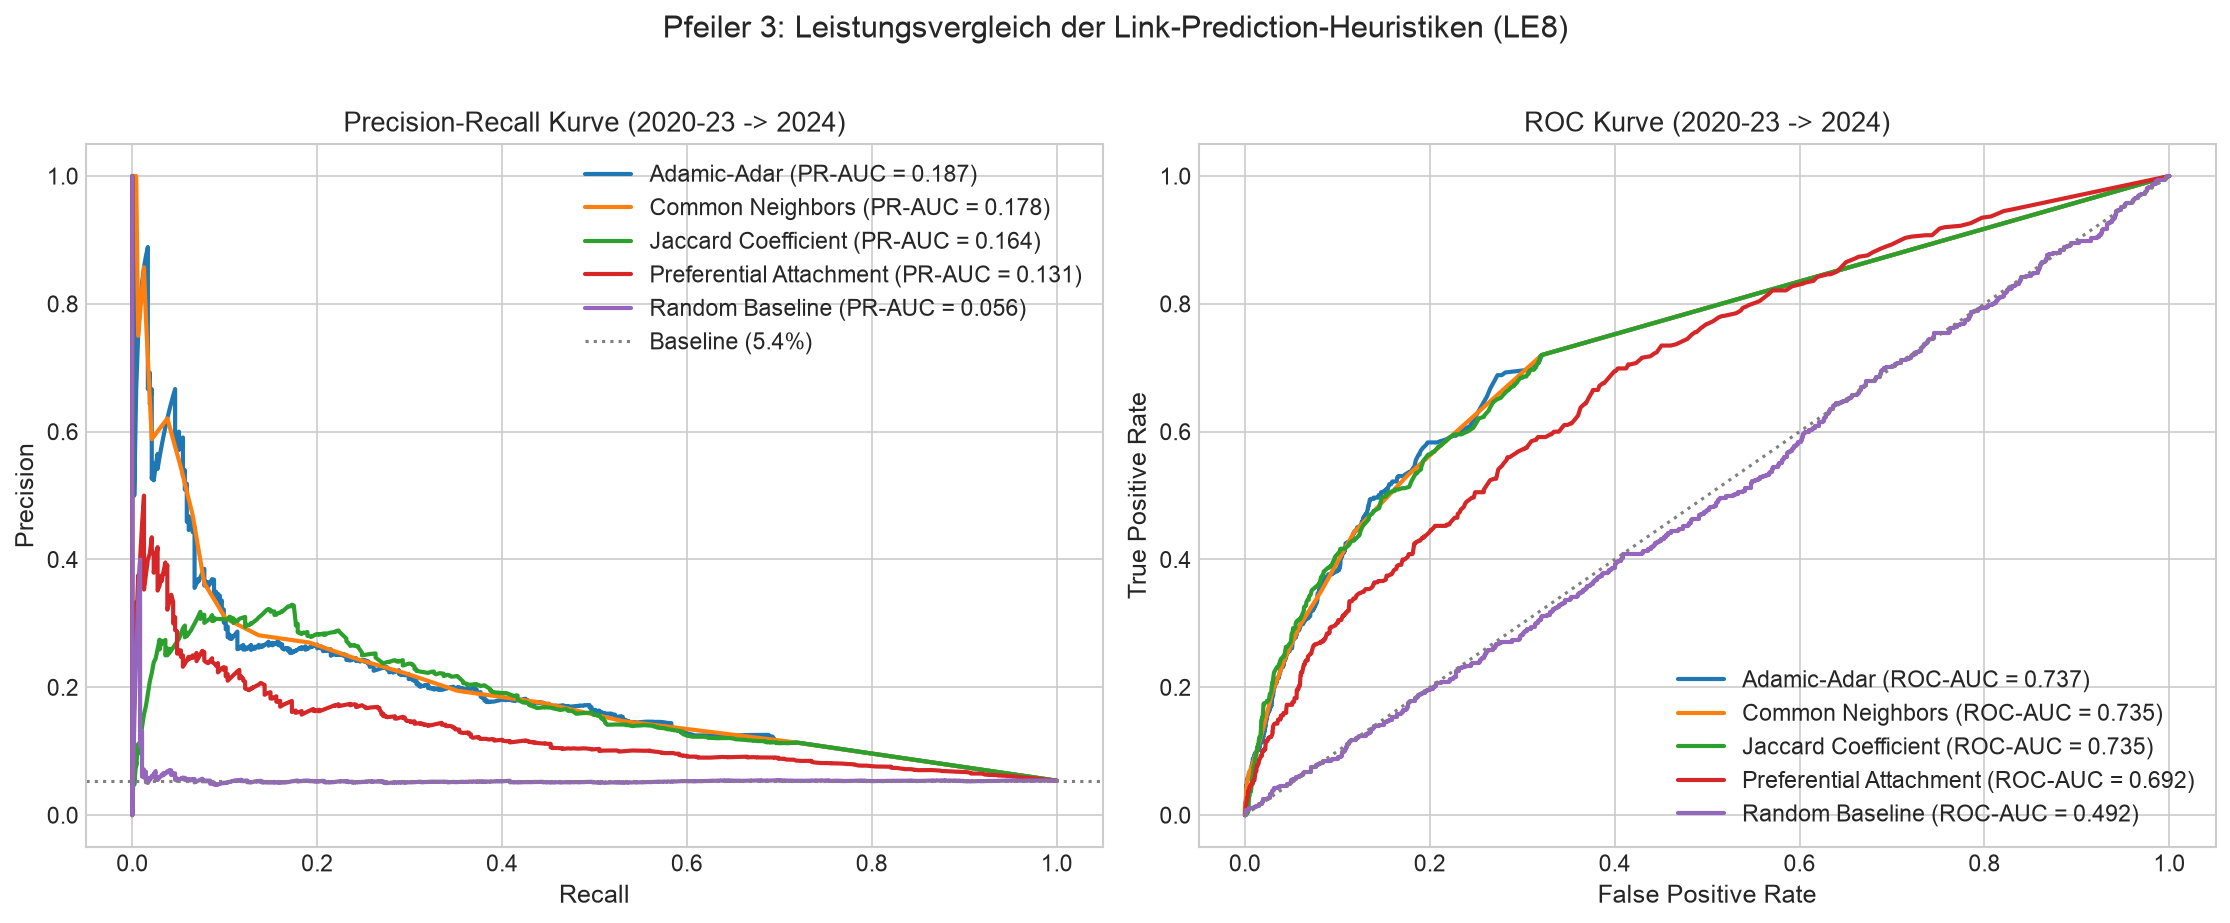

Bootstrap 95%-Konfidenzintervall für Differenz [PR-AUC(AA) - PR-AUC(PA)]: [0.0360, 0.0754]
Ergebnis: Adamic-Adar übertrifft Preferential Attachment signifikant (0 liegt unterhalb des 95%-CI).
Bester Algorithmus im finalen Fenster nach PR-AUC: Adamic-Adar (0.1872)


In [15]:
# Plot: Precision-Recall & ROC-Kurven für das finale Fenster (2020-23 -> 2024)
final_split_label = '2020-23 -> 2024'
res_final, y_true_final = all_results[final_split_label]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Precision-Recall Curve
for alg, m in res_final.items():
    p, r, _ = precision_recall_curve(y_true_final, m['scores'])
    axes[0].plot(r, p, linewidth=2, label=f"{alg} (PR-AUC = {m['PR-AUC (Avg Precision)']:.3f})")

axes[0].axhline(y_true_final.mean(), color='gray', linestyle=':', label=f'Baseline ({y_true_final.mean():.1%})')
axes[0].set_title(f'Precision-Recall Kurve ({final_split_label})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend(loc='upper right')

# ROC Curve
for alg, m in res_final.items():
    fpr, tpr, _ = roc_curve(y_true_final, m['scores'])
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{alg} (ROC-AUC = {m['ROC-AUC']:.3f})")

axes[1].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[1].set_title(f'ROC Kurve ({final_split_label})')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.suptitle('Pfeiler 3: Leistungsvergleich der Link-Prediction-Heuristiken (LE8)', y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig('out_plots/08_link_prediction_curves.png', dpi=300)
plt.show()

# Bootstrap-Konfidenzintervall: Adamic-Adar vs. Preferential Attachment
np.random.seed(42)
B_BOOT = 1000
aa_sc = res_final['Adamic-Adar']['scores']
pa_sc = res_final['Preferential Attachment']['scores']
diffs = np.zeros(B_BOOT)
n_samples = len(y_true_final)

for b in range(B_BOOT):
    idx = np.random.randint(0, n_samples, n_samples)
    ap_aa = average_precision_score(y_true_final[idx], aa_sc[idx])
    ap_pa = average_precision_score(y_true_final[idx], pa_sc[idx])
    diffs[b] = ap_aa - ap_pa

ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
print(f'Bootstrap 95%-Konfidenzintervall für Differenz [PR-AUC(AA) - PR-AUC(PA)]: [{ci_low:.4f}, {ci_high:.4f}]')

# Der Befund wird aus dem Intervall abgeleitet, nicht vorweggenommen.
if ci_low > 0:
    print('Ergebnis: Adamic-Adar übertrifft Preferential Attachment signifikant (0 liegt unterhalb des 95%-CI).')
elif ci_high < 0:
    print('Ergebnis: Preferential Attachment übertrifft Adamic-Adar signifikant (0 liegt oberhalb des 95%-CI).')
else:
    print('Ergebnis: Kein signifikanter Unterschied zwischen Adamic-Adar und Preferential Attachment (0 liegt im 95%-CI).')

# Bester Algorithmus nach PR-AUC, statt einer fest verdrahteten Annahme
best_algo = max(
    ((n, r['PR-AUC (Avg Precision)']) for n, r in res_final.items()),
    key=lambda x: x[1]
)
print(f'Bester Algorithmus im finalen Fenster nach PR-AUC: {best_algo[0]} ({best_algo[1]:.4f})')


## 5. Gesamtsynthese, Evidence Map & Akademische Deklarationen

### 5.1 Evidence Map (Zuordnung zu den Bewertungskriterien)

| Kriterium | Gewicht | Umsetzung im Projekt | Fundstelle |
| :--- | :---: | :--- | :--- |
| **1. Explorative Datenanalyse & Quelldaten-Validierung** | 1 | Stratifizierte Live-Validierung ($n=60$) gegen 20min.ch mit 100% Erreichbarkeit, 100% Titel- und 98.3% Datumsübereinstimmung. Systematische Fehlwert-Analyse: 41.4% der Kommentarwerte fehlen und werden als `NaN` geführt statt als 0. Token-basierte Entitäts-Resolution entfernt 133 institutionelle Knoten (Agenturen, Desks). | `src/00_eda.qmd`, `src/01_cleaning.qmd`, `data/ground_truth_validation.md`, `src/clean_dataset.py` |
| **2. Vielfalt der Netzwerk-Analysen** | 2 | Two-Mode-Modellierung und Newman-Projektion (LE3), Louvain-Communities, Cliquen und k-Core (LE4), Zentralität und Brokerage nach Burt (LE5), Netzwerk-Zentralisierung, Metriken und Connectivity (LE6), drei Hypothesentests inkl. QAP (LE7), rollierende Link-Prediction (LE8). Zwei komplementäre Netzwerke: Autoren-Kollaboration und semantische Keyword-Kookkurrenz. | Kapitel 2, 3 und 4 |
| **3. Nachvollziehbarkeit & korrekte Metriken** | 2 | Drei Nullmodelle unterschiedlicher Strenge: Label-Permutation, gradtreues Maslov-Sneppen-Rewiring, QAP mit gemeinsamer Zeilen-/Spalten-Permutation. Leakage-freie Leave-One-Out-JSD, unbalancierte Link-Prediction mit Bootstrap-CI. Alle Kernfunktionen sind durch Unit-Tests abgesichert. | 2.2, 2.3, 2.4, 2.5, Kap. 4; `python src/network_models.py` |
| **4. Anschaulichkeit der Resultate** | 1 | 13 beschriftete 300-DPI-Abbildungen, davon vier Netzwerk-Renderings, sowie drei `.gexf`-Exporte für Gephi. Jede Abbildung ist im Text referenziert und interpretiert. | `out_plots/`, `graphen/` |
| **5. Ausblick** | 1 | Methodische Erweiterungen und explizit benannte, bewusst nicht abgedeckte Lernergebnisse. | 5.2 |

---

### 5.2 Ausblick

**Nicht abgedeckte Lernergebnisse.** Zwei im Skript behandelte Analysefamilien wurden bewusst nicht umgesetzt und bilden den natürlichen nächsten Schritt:

1. **Diffusion (Kap. 13).** Das Kollaborationsnetzwerk eignet sich unmittelbar für Diffusionsmodelle: Wie breitet sich ein Thema, ein Format oder eine Recherchemethode über Koautorenschaften in der Redaktion aus? Ein Independent-Cascade-Modell auf $G_{collab}$ mit den Brokern aus 2.1 als Startmenge würde prüfen, ob genau jene Personen die effizientesten Multiplikatoren sind, die strukturell als Vermittler auffallen.
2. **Graphlets (Kap. 14).** Graphlet-Degree-Vektoren würden erlauben, Journalist:innen nicht nach ihrem Ressort, sondern nach ihrer strukturellen Rolle zu gruppieren. Damit liesse sich prüfen, ob es wiederkehrende Kollaborationsmuster gibt, die quer zur formalen Ressortgliederung liegen.

**Inhaltliche Erweiterungen.**

3. **Gerichtete und multirelationale Modellierung.** Die aktuelle Kollaborationskante ist ungerichtet. Mit der Autorenreihenfolge in der Byline (Erst- vs. Zweitautorschaft) liesse sich eine gerichtete Senioritätsrelation modellieren und mit dem semantischen Netzwerk zu einem multirelationalen Graphen kombinieren.
4. **Semantische Einbettungen.** Node2Vec- oder GNN-Einbettungen kombiniert mit deutschsprachigen Transformer-Vektoren würden inhaltliche Nähe feiner erfassen als die aktuelle Ressort-Verteilung.
5. **Dynamische Hypergraphen.** Redaktionsteams umfassen oft mehr als zwei Personen. Eine Hypergraph-Modellierung würde den Informationsverlust der paarweisen Projektion vermeiden.

**Was noch zu überarbeiten wäre.** Die Interaktionswerte (Likes, Shares, Kommentare) sind Momentaufnahmen zum Scraping-Zeitpunkt und driften gegenüber der Live-Plattform. Für belastbare Aussagen über Reichweite müssten sie zu mehreren Zeitpunkten erhoben werden. Ebenso fehlt bislang eine Auflösung von Namensvarianten derselben Person (etwa mit und ohne Zweitnamen).

---

### 5.3 Lessons Learned

1. **Entitäts-Resolution entscheidet über die Validität des ganzen Netzwerks.** Eine Filterung über exakte Zeichenkettenvergleiche reichte nicht aus. Zusammengesetzte Bylines wie `SDA fss`, `Rat Dpa` oder `Agence France-Presse` gelangten als vermeintliche Journalist:innen in den Graphen. `Agence France-Presse` mit 214 Artikeln lag sogar in der grössten Clique und blähte damit Kohäsions- und Zentralitätsmasse auf. Erst eine token-basierte Klassifikation entfernte 133 institutionelle Knoten. **Lehre:** Knoten-Identität ist keine Nebensache der Datenbereinigung, sondern bestimmt jedes nachgelagerte Mass.

2. **Fehlende Werte dürfen nicht zu Nullen werden.** 41.4% der Kommentarwerte fehlen, weil die Kommentarfunktion deaktiviert oder nicht erfasst war. Als 0 kodiert hätten sie „kein Interesse“ statt „keine Messung“ bedeutet und die Regression systematisch verzerrt.

3. **Nullmodelle müssen zur Datenstruktur passen.** In der Link-Prediction landeten Trainingskanten in der Negativmenge, weil Kantentupel unsortiert verglichen wurden. Beim QAP-Test korrelierten zunächst zwei Matrizen, die beide für nicht benachbarte Paare null sind, wodurch teilweise blosse Kanten-Kopräsenz gemessen wurde. Nach Korrektur auf eine über alle Dyaden definierte JSD-Matrix kehrte sich das Vorzeichen von $+0.148$ auf $-0.140$ um, was der Homophilie-Hypothese entspricht. **Lehre:** Ein plausibel aussehendes Ergebnis ist kein Korrektheitsnachweis. Beide Fehler wurden erst durch systematisches Code-Review und Unit-Tests sichtbar.

4. **Dichte-Vergleiche über Zeit sind ohne Normierung wertlos.** Der direkte Vergleich von Netzwerkdichten über Jahre mit unterschiedlicher Artikelzahl führt in die Irre. Ein fixiertes globales Vokabular, Mutual-$k$-NN-Sparsifizierung und normierte Zentralisierung waren notwendig, um überhaupt vergleichbare Topologien zu erhalten.

5. **Was wir künftig anders machen würden.** Unit-Tests für die Graphkonstruktion von Anfang an statt nachträglich, und ein Manifest mit Hashes für Roh- **und** abgeleitete Daten ab dem ersten Tag, damit Reproduzierbarkeit nicht rekonstruiert werden muss.

---

### 5.4 KI-Deklaration (AI-Use Disclosure)

> **HINWEIS: Dieser Abschnitt ist noch unvollständig.** Die Projektbeschreibung verlangt neben der Deklaration ausdrücklich die **Angabe der Prompts**. Die vollständige Prompt-Dokumentation ist in `TODO.md` als blockierender Punkt erfasst und muss vor der Abgabe in `docs/KI-Deklaration.md` ergänzt und hier verlinkt werden.

In Übereinstimmung mit den Richtlinien zur wissenschaftlichen Redlichkeit deklarieren wir:

- Für Code-Erstellung, Refactoring und Code-Review wurden generative KI-Werkzeuge eingesetzt (Antigravity/Codex sowie Claude Code).
- Themenwahl, Hypothesenbildung, Modellierungsentscheidungen und die Interpretation der Resultate liegen bei den Studierenden (Elias und Luca).
- Ein systematisches Code-Review deckte mehrere methodische Fehler in KI-generiertem Code auf (Datenleck in der Link-Prediction, fehlerhafte Leave-One-Out-Berechnung, unbedingt ausgegebene Signifikanzaussagen). Diese wurden korrigiert und sind durch Unit-Tests abgesichert. Die Befunde und ihre Behebung sind in `README.md` dokumentiert.
- **Ausstehend:** vollständige Prompt-Protokolle beider Werkzeuge.
